# SDS Mini Datathon 2026: Submission Notebook

**Team name:** Mixue lovers

**Members:** Xiong Zirui, Lee Juin Hsien Justin, Chew Zhan Shi Jordan

---

### Before you start
- Keep every section heading below, in this order. You may add cells and sub-headings inside each section.
- This notebook must run on **Python 3.14** using **Restart & Run All**, with no errors, in under **10 minutes**.
- Every chart in your deck must be generated in this notebook.
- Load data from the `data/` folder using relative paths only. Do not load data live from a website or API.
- Delete these instruction cells (the ones starting with *Instructions*) before submitting if you like, but keep the headings.

### Before you submit
1. Kernel → **Restart & Run All**, and check there are no errors.
2. Save the notebook with all outputs.
3. Export it as `main.html` (File → Save and Export Notebook As → HTML).
4. Zip the `TeamName/` folder: `main.ipynb`, `main.html`, `requirements.txt`, `deck.pdf`, `data/`.

## 1. Setup & Imports

*Instructions:* Import every library you use here. Each one must be listed, with its exact version, in `requirements.txt`.

In [29]:
import sys
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
import jinja2
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Add other libraries here, e.g.
# import seaborn as sns
# from sklearn.linear_model import LinearRegression

In [2]:
# Python version check: the judges' environment uses Python 3.14
print(f"Python version: {sys.version.split()[0]}")
if sys.version_info[:2] != (3, 14):
    print("WARNING: this notebook will be run on Python 3.14. Please test it on 3.14 before submitting.")

Python version: 3.14.6


In [3]:
# Random seed: keep this so your results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# If you use other libraries with randomness, set their seeds too,
# e.g. random_state=SEED in scikit-learn models

In [4]:
# Display settings (optional)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Data Ingestion

*Instructions:* Load all data from the `data/` folder using relative paths. If you use any additional public datasets, download them into `data/` and cite them in Section 9.

In [62]:
# Provided datasets (update the file names if needed)
coe = pd.read_csv("data/COEBiddingResultsPrices.csv")
registrations = pd.read_csv("data/NewRegistrationofCarsbyMake.csv")

print(f"COE bidding data: {coe.shape[0]:,} rows, {coe.shape[1]} columns")
print(f"Registration data: {registrations.shape[0]:,} rows, {registrations.shape[1]} columns")

COE bidding data: 1,990 rows, 7 columns
Registration data: 51,669 rows, 6 columns


In [41]:
coe.head()

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
0,2010-01,1,Category A,1152,1145,1342,18502
1,2010-01,1,Category B,687,679,883,19190
2,2010-01,1,Category C,173,173,265,19001
3,2010-01,1,Category D,373,365,509,889
4,2010-01,1,Category E,586,567,1011,19889


In [63]:
registrations.head()

,month,make,importer_type,fuel_type,vehicle_type,number
0,2016-01,ALFA ROMEO,NaN,Petrol,Hatchback,3.0
1,2016-01,ALPINA,NaN,Petrol,Hatchback,0.0
2,2016-01,ASTON MARTIN,NaN,Petrol,Hatchback,0.0
3,2016-01,AUDI,NaN,Petrol,Hatchback,45.0
4,2016-01,B.M.W.,NaN,Petrol,Hatchback,5.0


## 3. Data Cleaning

*Instructions:* Show every cleaning step, with a short note on why. For example: fixing data types, handling missing values, removing duplicates, and aggregating registrations to monthly totals before joining with the COE data.

**Reminder:** the two datasets overlap from January 2016 to May 2025.

### COE Dataframe

In [45]:
# split month into year and month
coe[['year', 'month']] = coe['month'].str.split('-', expand=True)
coe['year'] = coe['year'].astype(int)
coe['month'] = coe['month'].astype(int)
col = coe.pop("year")
coe.insert(0, "year", col)

# Create monthly date variable
coe["date"] = pd.to_datetime(
    coe[["year", "month"]].assign(day=1)
)

# change to int
cols = ["bids_received", "bids_success"]
coe[cols] = coe[cols].apply(
    lambda col: col.astype(str).str.replace(",", "", regex=False).astype(int))

coe['bids_success'] = coe['bids_success'].astype(int)
coe['bids_received'] = coe['bids_received'].astype(int)

In [9]:
# Create monthly date variable
coe["date"] = pd.to_datetime(
    coe[["year", "month"]].assign(day=1)
)

In [46]:
coe["d_pressure"] = np.where(
    coe["quota"] > 0,
    coe["bids_received"] / coe["quota"],
    np.nan
)

In [10]:
# Normalise premium column
coe["premium"] = coe["premium"] / 1000
coe["premium"].describe()

count    1990.000000
mean       53.769851
std        35.238011
min         0.852000
25%        29.902000
50%        50.514000
75%        76.610750
max       158.004000
Name: premium, dtype: float64

In [11]:
# generate summary for each column
summary = pd.DataFrame({
    "dtype": coe.dtypes,
    "non_null": coe.count(),
    "missing": coe.isna().sum(),
    "missing_pct": coe.isna().mean() * 100,
    "unique": coe.nunique()
})

display(summary)

,dtype,non_null,missing,missing_pct,unique
year,int64,1990,0,0.0,17
month,int64,1990,0,0.0,12
bidding_no,int64,1990,0,0.0,2
vehicle_class,str,1990,0,0.0,5
quota,int64,1990,0,0.0,867
bids_success,int64,1990,0,0.0,894
bids_received,int64,1990,0,0.0,1124
premium,float64,1990,0,0.0,1609
date,datetime64[us],1990,0,0.0,199


In [12]:
df = coe.loc[
    coe["vehicle_class"].isin(["Category A", "Category B"])
].copy()

# Sort chronologically
df = df.sort_values(
    ["year", "month", "bidding_no", "vehicle_class"]
).reset_index(drop=True)

# Check that each category appears only once per exercise
assert not df.duplicated(
    subset=["year", "month", "bidding_no", "vehicle_class"]
).any()

# Avoid division by zero
df["pressure"] = np.where(
    df["quota"] > 0,
    df["bids_received"] / df["quota"],
    np.nan
)

coe_wide = df.pivot(
    index=["year", "month", "bidding_no"],
    columns="vehicle_class",
    values=["premium", "pressure", "quota"]
)

# Flatten multi-level column names
coe_wide.columns = [
    f"{variable}_{category.replace('Category ', '')}"
    for variable, category in coe_wide.columns
]

coe_wide = coe_wide.reset_index()

# Sort chronologically
coe_wide = coe_wide.sort_values(
    ["year", "month", "bidding_no"]
).reset_index(drop=True)

# Create date column
coe_wide["date"] = pd.to_datetime(
    coe_wide[["year", "month"]].assign(day=1)
)

# Absolute premium gap (signed: B minus A)
coe_wide["gap"] = (
    coe_wide["premium_B"] - coe_wide["premium_A"]
)

# Percentage premium gap relative to Category A
coe_wide["gap_pct"] = np.where(
    coe_wide["premium_A"] > 0,
    coe_wide["gap"] / coe_wide["premium_A"] * 100,
    np.nan
)

# Difference in demand pressure
coe_wide["pressure_gap"] = (
    coe_wide["pressure_B"] - coe_wide["pressure_A"]
)

# Previous exercise premiums
coe_wide["premium_A_lag1"] = coe_wide["premium_A"].shift(1)
coe_wide["premium_B_lag1"] = coe_wide["premium_B"].shift(1)

# Previous exercise demand pressure
coe_wide["pressure_A_lag1"] = coe_wide["pressure_A"].shift(1)
coe_wide["pressure_B_lag1"] = coe_wide["pressure_B"].shift(1)

# Previous exercise premium gap
coe_wide["gap_lag1"] = coe_wide["gap"].shift(1)

In [13]:
# Check first few observations
display(coe_wide.head())

,year,month,bidding_no,premium_A,premium_B,pressure_A,pressure_B,quota_A,quota_B,date,gap,gap_pct,pressure_gap,premium_A_lag1,premium_B_lag1,pressure_A_lag1,pressure_B_lag1,gap_lag1
0,2010,1,1,18.502,19.190,1.164931,1.285298,1152.0,687.0,2010-01-01,0.688,3.718517,0.120368,NaN,NaN,NaN,NaN,NaN
1,2010,1,2,20.501,22.400,1.453519,1.541144,1151.0,717.0,2010-01-01,1.899,9.262963,0.087625,18.502,19.190,1.164931,1.285298,0.688
2,2010,2,1,19.989,23.180,1.149047,0.805893,1154.0,1154.0,2010-02-01,3.191,15.963780,-0.343154,20.501,22.400,1.453519,1.541144,1.899
3,2010,2,2,20.340,23.889,1.300523,1.395620,1148.0,685.0,2010-02-01,3.549,17.448378,0.095098,19.989,23.180,1.149047,0.805893,3.191
4,2010,3,1,20.802,26.389,1.531359,1.579942,1148.0,688.0,2010-03-01,5.587,26.857994,0.048583,20.340,23.889,1.300523,1.395620,3.549


### Registrations Dataframe

In [64]:
# split month into year and month
registrations[['year', 'month']] = registrations['month'].str.split('-', expand=True)
registrations['year'] = registrations['year'].astype(int)
registrations['month'] = registrations['month'].astype(int)
col = registrations.pop("year")
registrations.insert(0, "year", col)

#### importer_type column

In [65]:
# Missing importer type by year
registrations.groupby("year")["importer_type"].apply(
    lambda x: x.isna().mean() * 100
)

year
2016    100.0
2017    100.0
2018    100.0
2019    100.0
2020    100.0
2021    100.0
2022    100.0
2023      0.0
2024      0.0
2025      0.0
Name: importer_type, dtype: float64

Missing values for importer_type is highly structured as seen above. However, it is difficult to determine the significance of these NaN values without additional data. As this variable is not significant to our analysis, no modifications will be done.

#### fuel_type column

In [66]:
fuel_type_summary = (
    registrations
    .query("vehicle_type in ['Sedan', 'Hatchback', 'Coupe/ Convertible', 'Sports Utility Vehicle']")
    .groupby(["year", "fuel_type"])["number"]
    .sum()
    .unstack(fill_value=0)
)

display(fuel_type_summary)

fuel_type,Diesel,Diesel-Electric,Diesel-Electric (Plug-In),Electric,Others,Petrol,Petrol-Electric,Petrol-Electric (Plug-In)
year,,,,,,,,
2016,2449.0,0.0,0.0,0.0,3129.0,66401.0,0.0,0.0
2017,3488.0,0.0,0.0,0.0,8562.0,63449.0,0.0,0.0
2018,865.0,0.0,0.0,0.0,3139.0,62425.0,0.0,0.0
2019,448.0,0.0,0.0,0.0,4569.0,55862.0,0.0,0.0
2020,341.0,0.0,0.0,0.0,4707.0,33145.0,0.0,0.0
2021,363.0,0.0,0.0,0.0,11848.0,26883.0,0.0,0.0
2022,308.0,0.0,1.0,1786.0,6166.0,13439.0,4256.0,102.0
2023,101.0,1.0,0.0,5250.0,0.0,9531.0,9601.0,266.0
2024,39.0,1.0,0.0,13133.0,0.0,7016.0,15145.0,209.0


In [67]:
ev_makes = [
    "TESLA", "POLESTAR", "BLUECAR", "XPENG", "ZEEKR",
    "NETA", "SKYWORTH", "DEEPAL", "BYD", "SERES"
]

# Condition 1: Others + EV manufacturer → Electric
registrations.loc[
    (registrations["fuel_type"] == "Others") &
    (registrations["make"].isin(ev_makes)),
    "fuel_type"
] = "Electric"

# Condition 2: Remaining Others → Petrol
registrations.loc[
    registrations["fuel_type"] == "Others",
    "fuel_type"
] = "Petrol"

Distinction between electric and internal combustion vehicle engine vehicles is crucial. No additional information is available for the "others" fuel category. The significant number of "others" before 2022 cannot be ignored. We compromised by reassigning values to Electric/Petrol based on the car brand.

#### numbers column

In [68]:
# Missing number values by year
registrations.groupby("year")["number"].agg(
    total_rows="size",
    missing=lambda x: x.isna().sum(),
    missing_pct=lambda x: x.isna().mean() * 100
)

,total_rows,missing,missing_pct
year,,,
2016,4320,0,0.000000
2017,4265,0,0.000000
2018,3825,1219,31.869281
2019,4240,2617,61.721698
2020,4285,2833,66.114352
2021,4550,2836,62.329670
2022,5670,3924,69.206349
2023,9150,7214,78.841530
2024,7974,6216,77.953348


Missing values appeard from 2018 onwards. Further checks are conducted to determine if there is a change in data representation format.

In [69]:
# Determining number of missings values, 0s and non-zeros
zero_by_year = (
    registrations.groupby("year")["number"]
    .agg(
        total="size",
        missing=lambda x: x.isna().sum(),
        zeros=lambda x: (x == 0).sum(),
        positive=lambda x: (x > 0).sum()
    )
)

zero_by_year["zero_pct"] = (zero_by_year["zeros"] / zero_by_year["total"] * 100)
zero_by_year["missing_pct"] = (zero_by_year["missing"] / zero_by_year["total"] * 100)

display(zero_by_year)

,total,missing,zeros,positive,zero_pct,missing_pct
year,,,,,,
2016,4320,0,2791,1529,64.606481,0.000000
2017,4265,0,2488,1777,58.335287,0.000000
2018,3825,1219,1111,1495,29.045752,31.869281
2019,4240,2617,0,1623,0.000000,61.721698
2020,4285,2833,0,1452,0.000000,66.114352
2021,4550,2836,0,1714,0.000000,62.329670
2022,5670,3924,0,1746,0.000000,69.206349
2023,9150,7214,0,1936,0.000000,78.841530
2024,7974,6216,0,1758,0.000000,77.953348


2018 marked the transition from using "0" to "missing values" to represent the idea of "no entries for this category". The exact month of transition (July 2018) is shown in the table below.

In [70]:
# Determine exact month of transition from 0 to non-zero values in 2018
transition = (
    registrations[registrations["year"] == 2018]
    .groupby("month")["number"]
    .agg(
        total="size",
        zeros=lambda x: (x == 0).sum(),
        missing=lambda x: x.isna().sum(),
        positive=lambda x: (x > 0).sum()
    )
)

transition["zero_pct"] = (
    transition["zeros"] / transition["total"] * 100)

transition["missing_pct"] = (
    transition["missing"] / transition["total"] * 100)

display(transition)

,total,zeros,missing,positive,zero_pct,missing_pct
month,,,,,,
1,255,144,0,111,56.470588,0.000000
2,265,150,0,115,56.603774,0.000000
3,295,173,0,122,58.644068,0.000000
4,340,207,0,133,60.882353,0.000000
5,340,217,0,123,63.823529,0.000000
6,355,220,0,135,61.971831,0.000000
7,270,0,149,121,0.000000,55.185185
8,315,0,192,123,0.000000,60.952381
9,330,0,203,127,0.000000,61.515152


In [71]:
# Preserve original values
registrations["number_original"] = registrations["number"]

# Track imputed observations
registrations["number_imputed"] = registrations["number"].isna()

# Replace missing values with zero
registrations["number"] = registrations["number"].fillna(0).astype(int)

For quantitative analysis, we replaced missing values after July 2018 with 0. This change is tracked by the number_imputed column. Original data is also preserved for future validation of this method of cleaning. 

In [72]:
summary = pd.DataFrame({
    "dtype": registrations.dtypes,
    "non_null": registrations.count(),
    "missing": registrations.isna().sum(),
    "missing_pct": registrations.isna().mean() * 100,
    "unique": registrations.nunique()
})

display(summary)

,dtype,non_null,missing,missing_pct,unique
year,int64,51669,0,0.000000,10
month,int64,51669,0,0.000000,12
make,str,51669,0,0.000000,86
importer_type,str,20514,31155,60.297277,2
fuel_type,str,51669,0,0.000000,7
vehicle_type,str,51669,0,0.000000,7
number,int64,51669,0,0.000000,485
number_original,float64,22206,29463,57.022586,485
number_imputed,bool,51669,0,0.000000,2


In [73]:
registrations.head()

,year,month,make,importer_type,fuel_type,vehicle_type,number,number_original,number_imputed
0,2016,1,ALFA ROMEO,NaN,Petrol,Hatchback,3,3.0,False
1,2016,1,ALPINA,NaN,Petrol,Hatchback,0,0.0,False
2,2016,1,ASTON MARTIN,NaN,Petrol,Hatchback,0,0.0,False
3,2016,1,AUDI,NaN,Petrol,Hatchback,45,45.0,False
4,2016,1,B.M.W.,NaN,Petrol,Hatchback,5,5.0,False


## 4. Exploratory Data Analysis

*Instructions:* Explore the data to understand trends and patterns before modelling. Look out for structural breaks, such as the 2020 bidding suspension and the change in Category A/B definitions.

### COE Dataframe

In [24]:
def set_year_axis(ax, df):
    year_ticks = df.groupby("year")["exercise"].min()

    ax.set_xticks(year_ticks.values)
    ax.set_xticklabels(year_ticks.index)
    ax.set_xlabel("Year")

In [27]:
# COVID-19 bidding suspension
gap_start = pd.Timestamp("2020-04-01")
gap_end = pd.Timestamp("2020-07-01")

# Define significant events (replace with your actual dates)
event_dates = [
    # pd.Timestamp("2014-02-01"),
    # pd.Timestamp("2023-05-01"),
]

def date_to_exercise(date, df):
    """Convert a date to its approximate position on the exercise axis."""

    dates = pd.to_datetime(df["date"])

    # Find first exercise on or after the specified date
    matching = df.loc[dates >= date, "exercise"]

    if matching.empty:
        return np.nan

    return matching.iloc[0]

# Significant events
event_dates = [
    # pd.Timestamp("2014-02-01"),
    # pd.Timestamp("2023-05-01"),
]

def add_annotations(ax):

    # Red dashed lines for significant events
    for date in event_dates:
        ax.axvline(
            x=date,
            color="red",
            linestyle="--",
            linewidth=1.2,
            alpha=0.7
        )

    # Grey shaded region for COVID-19 suspension
    ax.axvspan(
        gap_start,
        gap_end,
        color="grey",
        alpha=0.2,
        zorder=0,
        label="COVID-19 Bidding Suspension"
    )

    # Black dotted borders
    for date in [gap_start, gap_end]:
        ax.axvline(
            x=date,
            color="black",
            linestyle=":",
            linewidth=1.5
        )

    # Format x-axis to display years
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

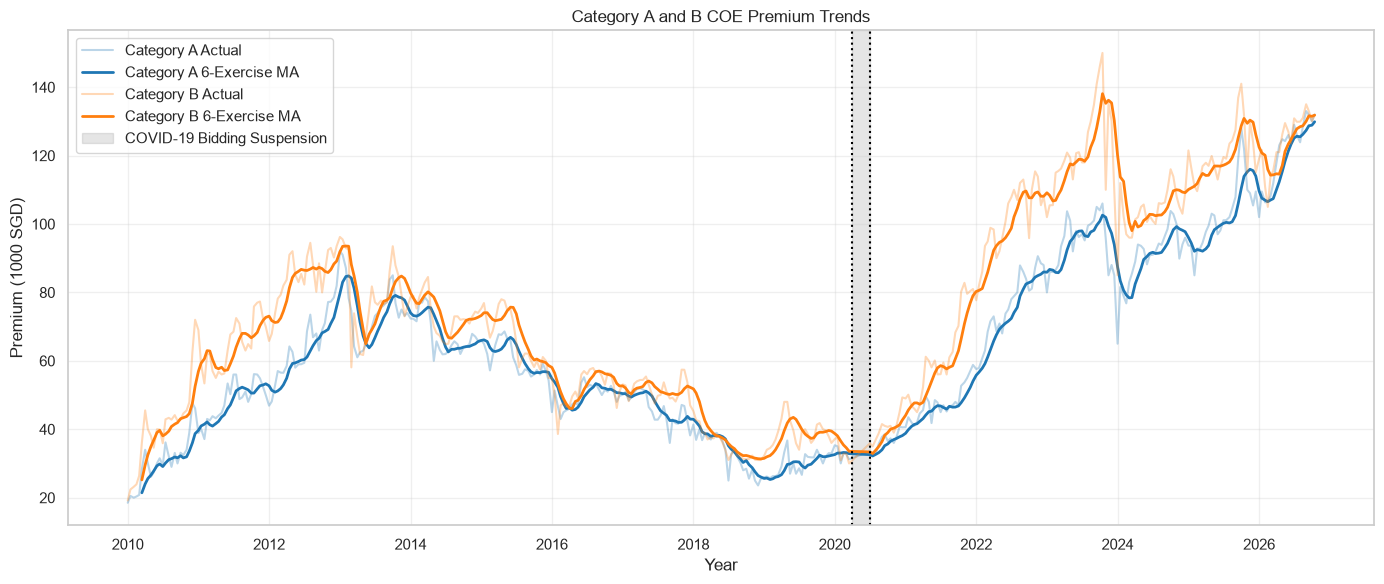

In [50]:
sns.set_theme(style="whitegrid")

# Create analysis dataset
df_analysis = coe_wide.copy()

# Sort chronologically
df_analysis = df_analysis.sort_values(
    ["year", "month", "bidding_no"]
).reset_index(drop=True)

# Create exercise index
df_analysis["exercise"] = np.arange(1, len(df_analysis) + 1)

# Create approximate dates for plotting
df_analysis["plot_date"] = (
    pd.to_datetime(df_analysis["date"])
    + pd.to_timedelta(
        (df_analysis["bidding_no"] - 1) * 14,
        unit="D"
    )
)

# Calculate 6-exercise moving averages
for category in ["A", "B"]:
    df_analysis[f"premium_{category}_ma6"] = (
        df_analysis[f"premium_{category}"]
        .rolling(window=6, min_periods=6)
        .mean()
    )

def plot_premium_trends(df, ax=None, annotations=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 6))

    colors = {"A": "tab:blue", "B": "tab:orange"}

    for category in ["A", "B"]:
        ax.plot(
            df["plot_date"],
            df[f"premium_{category}"],
            color=colors[category],
            alpha=0.3,
            label=f"Category {category} Actual"
        )

        ax.plot(
            df["plot_date"],
            df[f"premium_{category}_ma6"],
            color=colors[category],
            linewidth=2,
            label=f"Category {category} 6-Exercise MA"
        )

    if annotations:
        add_annotations(ax)

    ax.set(
        title="Category A and B COE Premium Trends",
        xlabel="Year",
        ylabel="Premium (1000 SGD)"
    )

    ax.legend()
    return ax

plot_premium_trends(df_analysis)
plt.tight_layout()
plt.show()

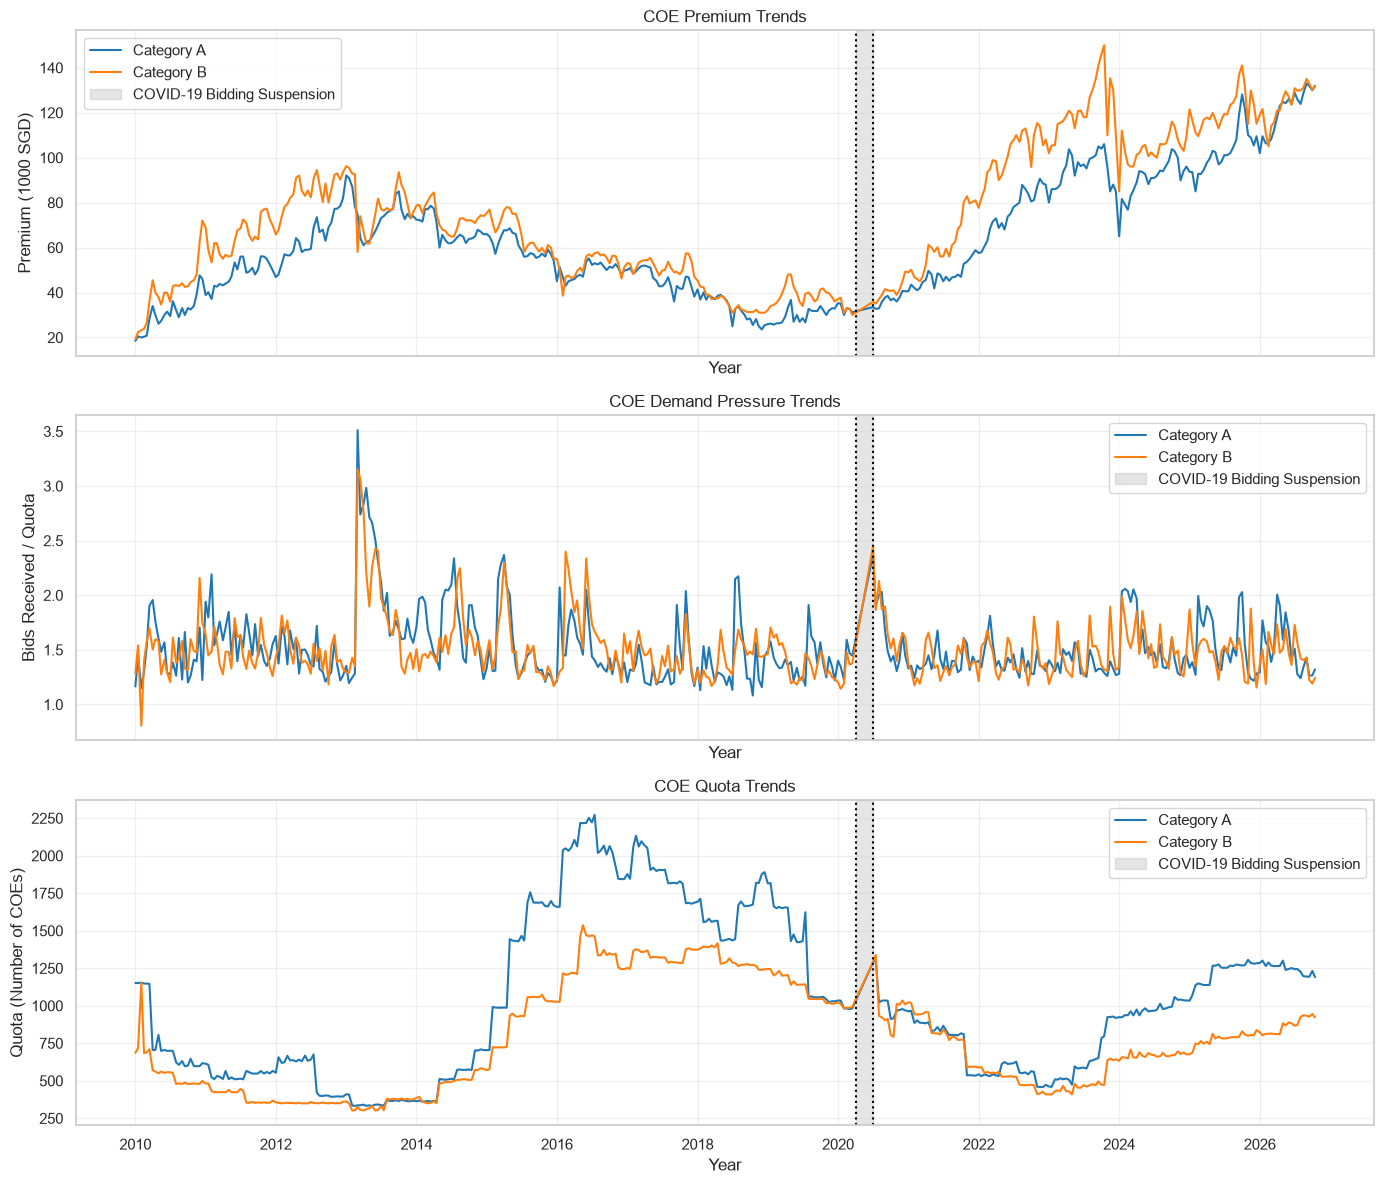

In [51]:
def plot_pressure_premium(df, annotations=True):

    df = df.copy()

    # Create plotting dates if they do not exist
    if "plot_date" not in df.columns:
        df["plot_date"] = (
            pd.to_datetime(df["date"])
            + pd.to_timedelta(
                (df["bidding_no"] - 1) * 14,
                unit="D"
            )
        )

    df = df.sort_values("plot_date")

    # Create three vertically stacked plots
    fig, axes = plt.subplots(
        3, 1,
        figsize=(14, 12),
        sharex=True
    )

    colors = {
        "A": "tab:blue",
        "B": "tab:orange"
    }

    variables = [
        ("premium", "COE Premium Trends", "Premium (1000 SGD)"),
        ("pressure", "COE Demand Pressure Trends", "Bids Received / Quota"),
        ("quota", "COE Quota Trends", "Quota (Number of COEs)")
    ]

    for i, (variable, title, ylabel) in enumerate(variables):

        for category in ["A", "B"]:
            axes[i].plot(
                df["plot_date"],
                df[f"{variable}_{category}"],
                color=colors[category],
                linewidth=1.5,
                label=f"Category {category}"
            )

        axes[i].set(
            title=title,
            ylabel=ylabel
        )

        if annotations:
            add_annotations(axes[i])

        axes[i].legend()

    axes[-1].set_xlabel("Year")

    plt.tight_layout()

    return fig, axes

fig, axes = plot_pressure_premium(coe_wide)
plt.show()

In general, premiums exibit a negative correlation with quota. From 2023-2026, there is a divergence of cat A and B quotas. Compared to the other divergence between 2015-2019, difference between cat A and B premiums is more significant. 

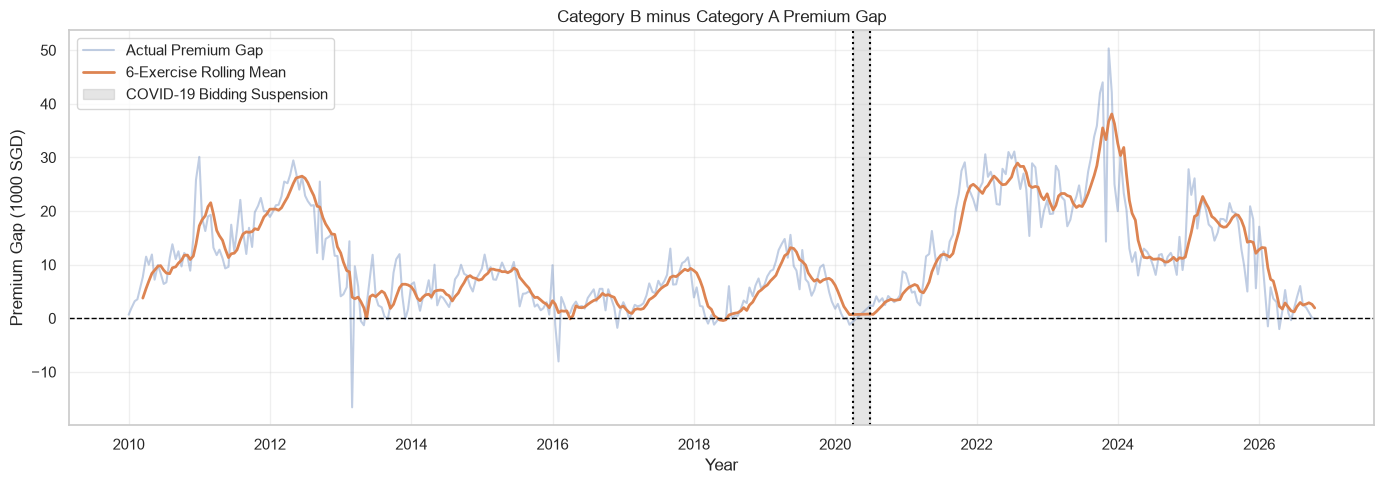

In [55]:
fig, ax = plt.subplots(figsize=(14, 5))

df_analysis["gap_ma6"] = df_analysis[f"premium_B_ma6"] - df_analysis[f"premium_A_ma6"]

ax.plot(
    df_analysis["plot_date"],
    df_analysis["gap"],
    alpha=0.35,
    label="Actual Premium Gap"
)

ax.plot(
    df_analysis["plot_date"],
    df_analysis["gap_ma6"],
    linewidth=2,
    label="6-Exercise Rolling Mean"
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

add_annotations(ax)

ax.set(
    title="Category B minus Category A Premium Gap",
    ylabel="Premium Gap (1000 SGD)"
)

ax.legend()
plt.tight_layout()
plt.show()

The premium gap between cat A and B is currently near the lowest point within the time period captured by the data. Despite relatively higher cat A quotas between 2023-2026, demand pressure for cat A is also slightly higher than that of cat B. This could indicate a shift in demand from cat B to A, driving the convergence in price.

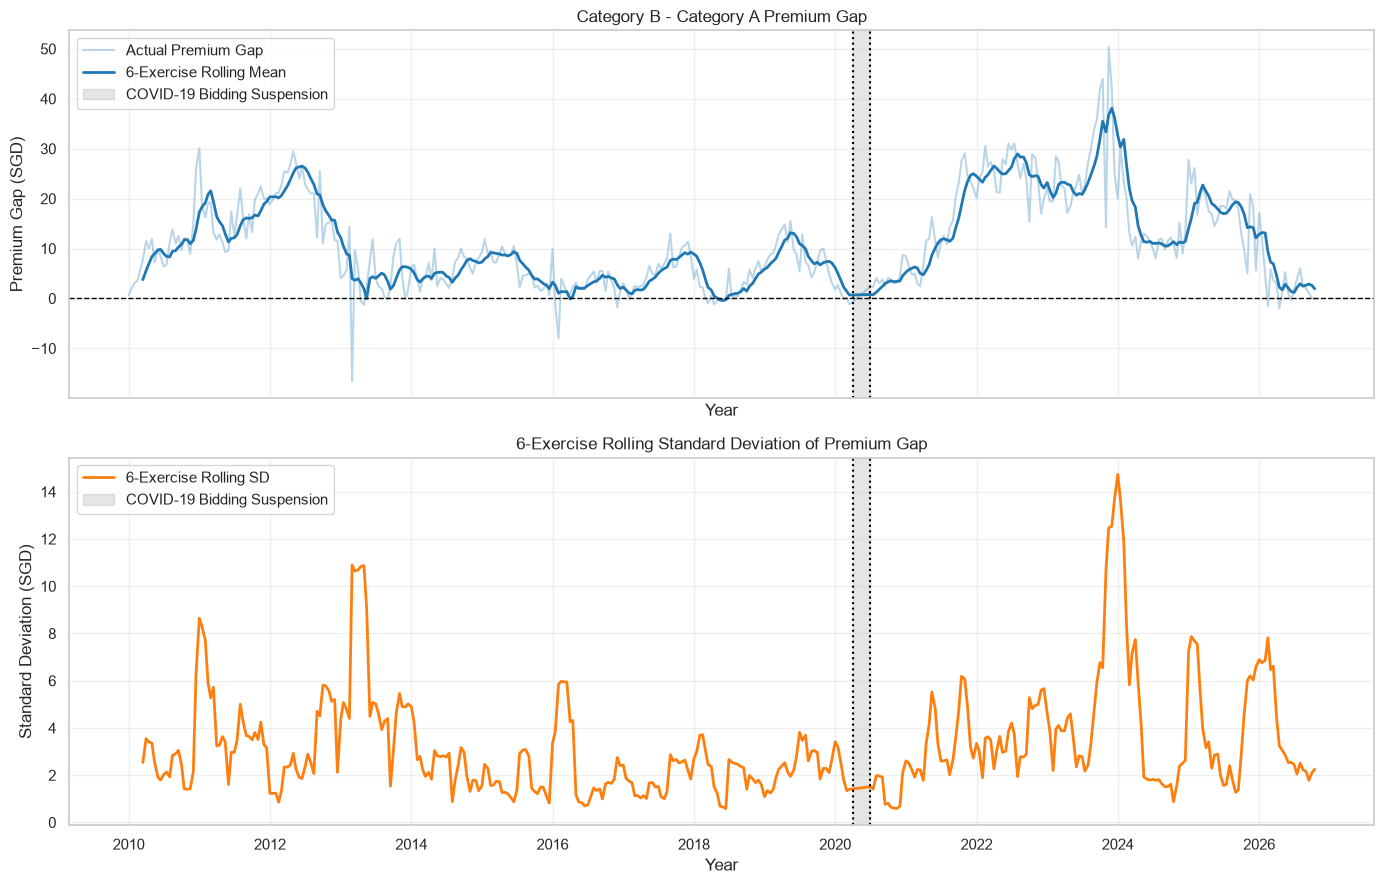

In [60]:
# Sort chronologically
df_analysis = df_analysis.sort_values(
    ["year", "month", "bidding_no"]
).reset_index(drop=True)

# Calculate premium gap
df_analysis["gap"] = (
    df_analysis["premium_B"] - df_analysis["premium_A"]
)

# Calculate 6-exercise rolling statistics
df_analysis["gap_ma6"] = (
    df_analysis["gap"]
    .rolling(window=6, min_periods=6)
    .mean()
)

df_analysis["gap_sd6"] = (
    df_analysis["gap"]
    .rolling(window=6, min_periods=6)
    .std()
)

# Create figure
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

# Plot 1: Premium gap and rolling mean
axes[0].plot(
    df_analysis["plot_date"],
    df_analysis["gap"],
    color="tab:blue",
    alpha=0.3,
    label="Actual Premium Gap"
)

axes[0].plot(
    df_analysis["plot_date"],
    df_analysis["gap_ma6"],
    color="tab:blue",
    linewidth=2,
    label="6-Exercise Rolling Mean"
)

axes[0].axhline(
    0, color="black", linestyle="--", linewidth=1
)

axes[0].set(
    title="Category B - Category A Premium Gap",
    ylabel="Premium Gap (SGD)"
)

# Plot 2: Rolling standard deviation of premium gap
axes[1].plot(
    df_analysis["plot_date"],
    df_analysis["gap_sd6"],
    color="tab:orange",
    linewidth=2,
    label="6-Exercise Rolling SD"
)

axes[1].set(
    title="6-Exercise Rolling Standard Deviation of Premium Gap",
    ylabel="Standard Deviation (SGD)"
)

# Add event annotations
for ax in axes:
    add_annotations(ax)
    ax.legend()

plt.tight_layout()
plt.show()

Falling premium gap also coincides with lower standard deviation, indicating a more stable convergence. This could be similar to the 2014-2020 period, marked by low premium gaps and standard deviation.

### Registrations Dataframe

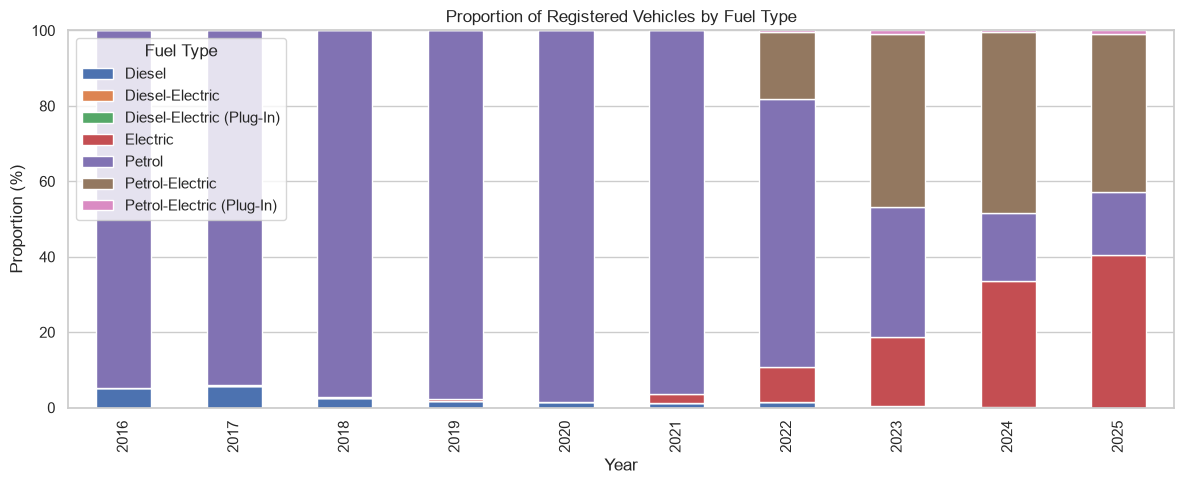

In [74]:
fuel_pct = (
    registrations
    .groupby(["year", "fuel_type"])["number"]
    .sum()
    .unstack(fill_value=0)
)

fuel_pct = fuel_pct.div(fuel_pct.sum(axis=1), axis=0) * 100

fuel_pct.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Proportion of Registered Vehicles by Fuel Type")
plt.xlabel("Year")
plt.ylabel("Proportion (%)")
plt.legend(title="Fuel Type")
plt.tight_layout()
plt.show()

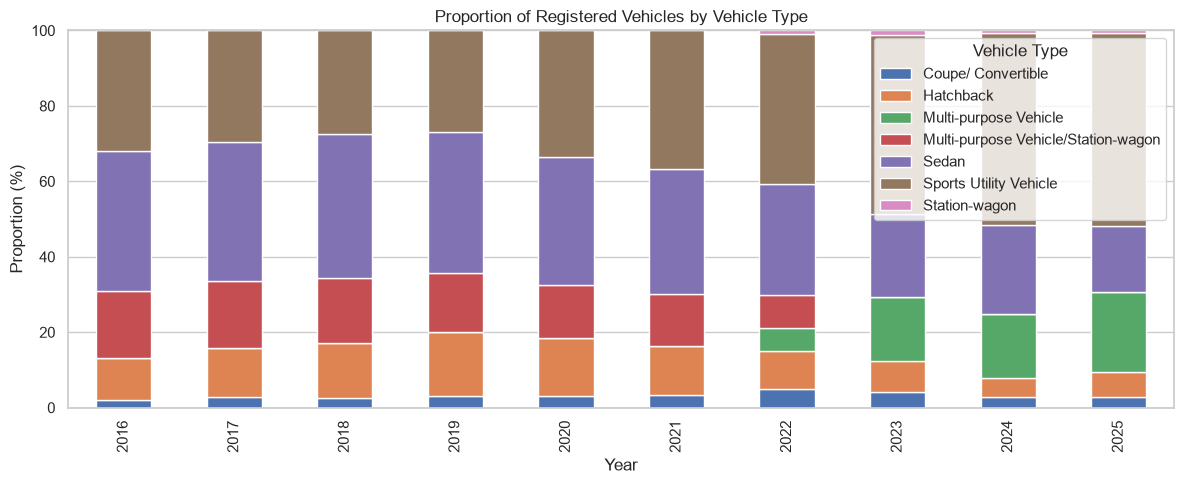

In [75]:
type_pct = (
    registrations
    .groupby(["year", "vehicle_type"])["number"]
    .sum()
    .unstack(fill_value=0)
)

type_pct = type_pct.div(type_pct.sum(axis=1), axis=0) * 100

type_pct.plot(kind="bar", stacked=True, figsize=(12, 5))

plt.title("Proportion of Registered Vehicles by Vehicle Type")
plt.xlabel("Year")
plt.ylabel("Proportion (%)")
plt.legend(title="Vehicle Type")
plt.tight_layout()
plt.show()

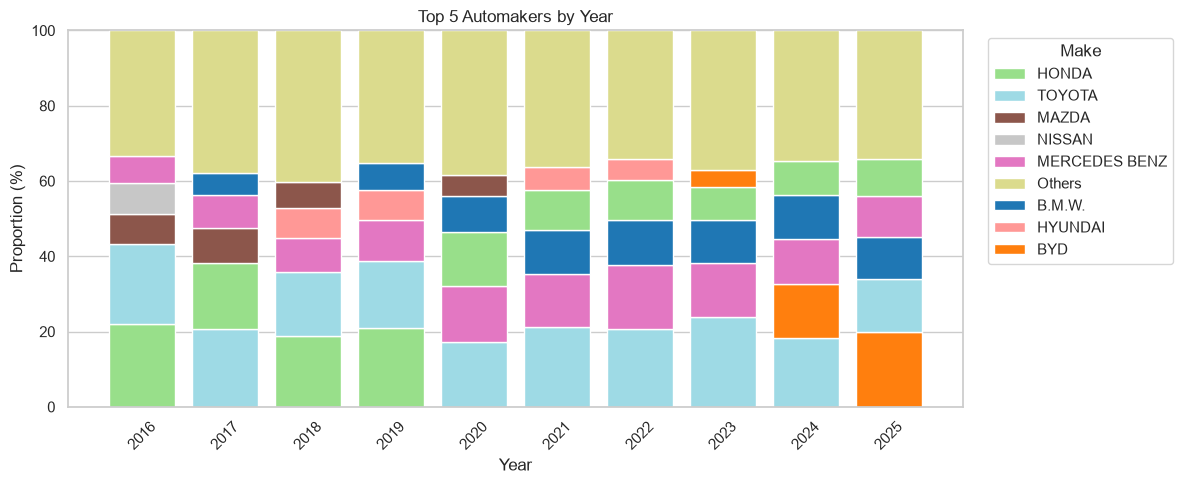

In [76]:
# Calculate registrations by year and make
make_df = (
    registrations
    .groupby(["year", "make"], as_index=False)["number"]
    .sum()
)

# Rank automakers within each year
make_df["rank"] = (
    make_df.groupby("year")["number"]
    .rank(method="first", ascending=False)
)

# Group makes outside top 5 as Others
make_df["make"] = make_df["make"].where(
    make_df["rank"] <= 5, "Others"
)

# Calculate yearly proportions
make_pct = (
    make_df
    .groupby(["year", "make"])["number"]
    .sum()
    .unstack(fill_value=0)
)

make_pct = make_pct.div(make_pct.sum(axis=1), axis=0) * 100

# Assign consistent colors to makes
colors = dict(zip(
    make_pct.columns,
    plt.cm.tab20(np.linspace(0, 1, len(make_pct.columns)))
))

# Plot
fig, ax = plt.subplots(figsize=(12, 5))

for i, (year, row) in enumerate(make_pct.iterrows()):
    bottom = 0

    # Sort top 5 from largest to smallest
    sorted_makes = row.drop("Others").sort_values(ascending=False)

    # Keep Others at the top
    sorted_makes = pd.concat([sorted_makes, row[["Others"]]])

    for make, pct in sorted_makes.items():
        if pct > 0:
            ax.bar(
                i, pct,
                bottom=bottom,
                color=colors[make],
                label=make
            )
            bottom += pct

# Formatting
ax.set_xticks(range(len(make_pct.index)))
ax.set_xticklabels(make_pct.index, rotation=45)
ax.set_title("Top 5 Automakers by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Proportion (%)")
ax.set_ylim(0, 100)

# Remove duplicate legend entries
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))

ax.legend(
    unique.values(), unique.keys(),
    title="Make",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [77]:
top10_yearly = (
    registrations
    .groupby(["year", "make"])["number"]
    .sum()
    .reset_index()
    .sort_values(["year", "number"], ascending=[True, False])
    .groupby("year")
    .head(10)
)
top10_table = (
    top10_yearly
    .assign(rank=lambda x: x.groupby("year").cumcount() + 1)
    .pivot(index="rank", columns="year", values="make")
)
display(
    top10_table.style.map(
        lambda x: "background-color: green" if x in ev_makes else ""
    )
)

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rank,,,,,,,,,,
1,HONDA,TOYOTA,HONDA,HONDA,TOYOTA,TOYOTA,TOYOTA,TOYOTA,TOYOTA,BYD
2,TOYOTA,HONDA,TOYOTA,TOYOTA,MERCEDES BENZ,MERCEDES BENZ,MERCEDES BENZ,MERCEDES BENZ,BYD,TOYOTA
3,MAZDA,MAZDA,MERCEDES BENZ,MERCEDES BENZ,HONDA,B.M.W.,B.M.W.,B.M.W.,MERCEDES BENZ,B.M.W.
4,NISSAN,MERCEDES BENZ,HYUNDAI,HYUNDAI,B.M.W.,HONDA,HONDA,HONDA,B.M.W.,MERCEDES BENZ
5,MERCEDES BENZ,B.M.W.,MAZDA,B.M.W.,MAZDA,HYUNDAI,HYUNDAI,BYD,HONDA,HONDA
6,B.M.W.,NISSAN,B.M.W.,KIA,AUDI,MAZDA,MAZDA,NISSAN,TESLA,TESLA
7,MITSUBISHI,KIA,NISSAN,MAZDA,HYUNDAI,AUDI,TESLA,MAZDA,HYUNDAI,HYUNDAI
8,SUBARU,HYUNDAI,KIA,MITSUBISHI,KIA,NISSAN,NISSAN,HYUNDAI,NISSAN,KIA
9,VOLKSWAGEN,MITSUBISHI,MITSUBISHI,AUDI,NISSAN,KIA,AUDI,KIA,MAZDA,MAZDA


## 5. Analysis & Modelling

*Instructions:* Explain your method and why you chose it. If you build a model:
- Use **time-based validation** (train on earlier data, test on later data). Do not use random splits.
- Compare against **simple baselines**, such as the previous round's premium or a rolling average.
- **Bids received** is only known after a round closes. Use it to explain premiums, not to forecast them.
- A merged Category A/B premium cannot be observed. If you model one, state your assumption and test how sensitive your results are to it.

A model is not required. A well-reasoned statistical or descriptive analysis is fine.

In [ ]:
# Linear regression
# Category A
df_A = pd.DataFrame({
    "premium": premium["Category A"],
    "premium_lag1": premium_lag1["Category A"],
    "pressure_lag1": pressure_lag1["Category A"]
}).dropna()

# Category B
df_B = pd.DataFrame({
    "premium": premium["Category B"],
    "premium_lag1": premium_lag1["Category B"],
    "pressure_lag1": pressure_lag1["Category B"]
}).dropna()

# Training: up to 2024
train_A = df_A.loc[: "2024-12-01"]
train_B = df_B.loc[: "2024-12-01"]

# Validation: 2025-2026
val_A = df_A.loc["2025-01-01":"2026-12-01"]
val_B = df_B.loc["2025-01-01":"2026-12-01"]

# Model 1: Category A
X_train_A = sm.add_constant(train_A[["premium_lag1", "pressure_lag1"]])
y_train_A = train_A["premium"]

lm1 = sm.OLS(y_train_A, X_train_A).fit()

# Model 2: Category B
X_train_B = sm.add_constant(train_B[["premium_lag1", "pressure_lag1"]])
y_train_B = train_B["premium"]

lm2 = sm.OLS(y_train_B, X_train_B).fit()

# Regression summaries
print("Category A")
print(lm1.summary())

print("\nCategory B")
print(lm2.summary())

# Category A predictions
X_val_A = sm.add_constant(
    val_A[["premium_lag1", "pressure_lag1"]],
    has_constant="add"
)

pred_A = lm1.predict(X_val_A)

# Category B predictions
X_val_B = sm.add_constant(
    val_B[["premium_lag1", "pressure_lag1"]],
    has_constant="add"
)

pred_B = lm2.predict(X_val_B)

# Evaluation function
def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Category A": evaluate(val_A["premium"], pred_A),
    "Category B": evaluate(val_B["premium"], pred_B)
}).T

display(results.round(3))

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Category A
axes[0].plot(val_A.index, val_A["premium"], label="Actual")
axes[0].plot(val_A.index, pred_A, label="Predicted", linestyle="--")
axes[0].set_title("Category A: Actual vs Predicted Premium")
axes[0].set_ylabel("Premium (SGD)")
axes[0].legend()

# Category B
axes[1].plot(val_B.index, val_B["premium"], label="Actual")
axes[1].plot(val_B.index, pred_B, label="Predicted", linestyle="--")
axes[1].set_title("Category B: Actual vs Predicted Premium")
axes[1].set_ylabel("Premium (SGD)")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Correlaton matrix for premium and demand pressure (current month)
# Combine monthly premiums and demand pressure
corr_df = pd.DataFrame({
    "Premium A": premium["Category A"],
    "Premium B": premium["Category B"],
    "Pressure A": pressure["Category A"],
    "Pressure B": pressure["Category B"],
})

# Calculate correlation matrix
corr_matrix = corr_df.corr()

display(corr_matrix.round(3))

In [ ]:
# Prepare data
plot_df = pd.DataFrame({
    "Premium Difference": premium["Category B"] - premium["Category A"],
    "Pressure A": pressure["Category A"]
}).dropna()

# Scatter plot with regression line
plt.figure(figsize=(8, 5))

sns.regplot(
    data=plot_df,
    x="Pressure A",
    y="Premium Difference",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Category A Demand Pressure vs Premium Difference (B - A)")
plt.xlabel("Category A Demand Pressure (Bids / Quota)")
plt.ylabel("Premium Difference (SGD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Pearson correlation
print("Correlation:", round(
    plot_df["Pressure A"].corr(plot_df["Premium Difference"]), 3
))

In [ ]:
# Prepare data
corr_df = pd.DataFrame({
    "Pressure A": pressure["Category A"],
    "Premium Difference": premium["Category B"] - premium["Category A"]
}).dropna()

# Calculate yearly correlations
yearly_corr = (
    corr_df
    .groupby(corr_df.index.year)
    .apply(lambda x: x["Pressure A"].corr(x["Premium Difference"]))
)

# Plot
plt.figure(figsize=(12, 5))
plt.bar(yearly_corr.index, yearly_corr.values)

plt.title("Yearly Correlation: Category A Demand Pressure vs Premium Difference")
plt.xlabel("Year")
plt.ylabel("Pearson Correlation")
plt.ylim(-1, 1)
plt.axhline(0, color="black", linestyle="--")
plt.xticks(yearly_corr.index, rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Monthly vehicle registrations by fuel type
ev_df = registrations.copy()

ev_df["date"] = pd.to_datetime(
    ev_df[["year", "month"]].assign(day=1)
)

# Calculate monthly EV share
ev_df["electric_number"] = np.where(
    ev_df["fuel_type"].str.strip().str.lower() == "electric",
    ev_df["number"],
    0
)

ev_share = (
    ev_df
    .groupby("date")
    .agg(
        electric=("electric_number", "sum"),
        total=("number", "sum")
    )
)

ev_share["ev_share"] = (
    ev_share["electric"] / ev_share["total"].replace(0, np.nan)
)

ev_share = ev_share["ev_share"]

In [ ]:
# monthly quota by vehicle class
quota = (
    ab_df
    .groupby(["date", "vehicle_class"])["quota"]
    .sum()
    .unstack()
    .reindex(premium.index)
)

In [ ]:
# Prepare registration data
ev_df = registrations.copy()

ev_df["date"] = pd.to_datetime(
    ev_df[["year", "month"]].assign(day=1)
)

# Identify electric vehicles
ev_df["electric_number"] = np.where(
    ev_df["fuel_type"].str.strip().str.lower() == "electric",
    ev_df["number"],
    0
)

# Monthly EV proportion
ev_share = (
    ev_df
    .groupby("date")
    .agg(
        electric=("electric_number", "sum"),
        total=("number", "sum")
    )
)

ev_share["ev_share"] = (
    ev_share["electric"] /
    ev_share["total"].replace(0, np.nan)
)

# Previous month's EV proportion
ev_share_lag1 = ev_share["ev_share"].reindex(premium.index).shift(1)

# Monthly quota by COE category
quota = (
    ab_df
    .groupby(["date", "vehicle_class"])["quota"]
    .sum(min_count=1)
    .unstack()
    .reindex(premium.index)
)

# Previous month's quota
quota_lag1 = quota.shift(1)

# Category A
df_A = pd.DataFrame({
    "premium": premium["Category A"],
    "ev_share_lag1": ev_share_lag1,
    "pressure_ma3": pressure_ma3["Category A"],
    "premium_ma3": premium_ma3["Category A"],
    "quota_lag1": quota_lag1["Category A"]
})

# Category B
df_B = pd.DataFrame({
    "premium": premium["Category B"],
    "ev_share_lag1": ev_share_lag1,
    "pressure_ma3": pressure_ma3["Category B"],
    "premium_ma3": premium_ma3["Category B"],
    "quota_lag1": quota_lag1["Category B"]
})

# Restrict to overlapping period
df_A = df_A.loc["2016-01-01":"2025-05-01"].dropna()
df_B = df_B.loc["2016-01-01":"2025-05-01"].dropna()

# Training: 2016-2024
train_A = df_A.loc[:"2024-12-01"]
train_B = df_B.loc[:"2024-12-01"]

# Validation: Jan-May 2025
val_A = df_A.loc["2025-01-01":]
val_B = df_B.loc["2025-01-01":]
predictors = [
    "ev_share_lag1",
    "pressure_ma3",
    "premium_ma3",
    "quota_lag1"
]

# Category A
X_train_A = sm.add_constant(train_A[predictors])
y_train_A = train_A["premium"]

lm3 = sm.OLS(y_train_A, X_train_A).fit()

# Category B
X_train_B = sm.add_constant(train_B[predictors])
y_train_B = train_B["premium"]

lm4 = sm.OLS(y_train_B, X_train_B).fit()

print("Category A")
print(lm3.summary())

print("\nCategory B")
print(lm4.summary())

In [ ]:
predictors = [
    "ev_share_lag1",
    "pressure_ma3",
    "premium_ma3",
    "quota_lag1"
]

# Category A
X_val_A = sm.add_constant(
    val_A[predictors],
    has_constant="add"
)

pred_A = lm3.predict(X_val_A)

# Category B
X_val_B = sm.add_constant(
    val_B[predictors],
    has_constant="add"
)

pred_B = lm4.predict(X_val_B)

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Category A
axes[0].plot(val_A.index, val_A["premium"], label="Actual")
axes[0].plot(val_A.index, pred_A, label="Predicted", linestyle="--")
axes[0].set_title("Category A: Actual vs Predicted Premium")
axes[0].set_ylabel("Premium (SGD)")
axes[0].legend()

# Category B
axes[1].plot(val_B.index, val_B["premium"], label="Actual")
axes[1].plot(val_B.index, pred_B, label="Predicted", linestyle="--")
axes[1].set_title("Category B: Actual vs Predicted Premium")
axes[1].set_ylabel("Premium (SGD)")
axes[1].set_xlabel("Date")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Visualisations

*Instructions:* Generate every chart used in your deck here. Each chart should have a clear title, labelled axes with units, and a one-line takeaway in a markdown cell below it.

In [ ]:
# Defined functions to annotate the graphs with significant events and gaps
# Significant COE event dates
event_dates = pd.to_datetime([
    "2014-02-01",
    "2018-02-01",
    "2022-05-01",
    "2022-07-01"
])

# COVID-19 bidding suspension
gap_start = pd.Timestamp("2020-04-01")
gap_end = pd.Timestamp("2020-07-01")

def add_annotations(ax):
    # Red dashed lines for significant events
    for date in event_dates:
        ax.axvline(
            x=date,
            color="red",
            linestyle="--",
            linewidth=1.2,
            alpha=0.7
        )

    # Grey shaded region
    ax.axvspan(
        gap_start, gap_end,
        color="grey",
        alpha=0.2,
        zorder=0
    )

    # Black dotted borders
    for date in [gap_start, gap_end]:
        ax.axvline(
            x=date,
            color="black",
            linestyle=":",
            linewidth=1.5
        )

    ax.grid(alpha=0.3)

In [ ]:
# Calculate total monthly quota for Categories A and B
monthly_quota = (
    ab_df
    .groupby("date")["quota"]
    .sum()
    .reindex(premium.index)
)

# Preserve the Apr-Jun 2020 gap
monthly_quota.loc["2020-04-01":"2020-06-01"] = float("nan")

fig, ax = plt.subplots(figsize=(13, 5))

# Left axis: COE premiums
ax.plot(
    premium.index,
    premium["Category A"],
    label="Category A"
)

ax.plot(
    premium.index,
    premium["Category B"],
    label="Category B"
)

# Right axis: Total monthly quota
ax2 = ax.twinx()

ax2.plot(
    monthly_quota.index,
    monthly_quota,
    color="green",
    linestyle="--",
    alpha=0.7,
    label="Total Quota"
)

# Existing annotations
add_annotations(ax)

# Labels
ax.set_title("Monthly Average COE Premium and Total Quota")
ax.set_ylabel("Premium (1000 SGD)")
ax.set_xlabel("Date")
ax2.set_ylabel("Total Monthly Quota", color="green")
ax2.tick_params(axis="y", labelcolor="green")

# Combined legend
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

**Takeaway:** Cat A and B prices exibit a negative correlation with total quota.

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    premium.index,
    premium["difference"],
    color="purple",
    label="Category B - Category A"
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

add_annotations(ax)

ax.set_title("COE Premium Difference (B - A)")
ax.set_ylabel("Premium Difference (1000 SGD)")
ax.set_xlabel("Date")
ax.legend()

plt.tight_layout()
plt.show()

**Takeaway:** [One sentence on what this chart shows]

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    pressure.index,
    pressure["Category A"],
    label="Category A"
)

ax.plot(
    pressure.index,
    pressure["Category B"],
    label="Category B"
)

add_annotations(ax)

ax.set_title("Monthly Average Demand Pressure")
ax.set_ylabel("Bids / Quota")
ax.set_xlabel("Date")
ax.legend()

plt.tight_layout()
plt.show()

**Takeaway:** [One sentence on what this chart shows]

## 7. Key Findings & Recommendation

*Instructions:* Summarise your main findings and state your recommendation. This should match your deck.

**Recommendation:** [Your recommendation in one or two sentences]

**Key findings:**
1. [Finding 1]
2. [Finding 2]
3. [Finding 3]

## 8. Assumptions & Limitations

**What the data shows:**
- [Supported directly by the data]

**What we assumed:**
- [Assumption, and how sensitive your conclusions are to it]

**What is speculation:**
- [Interpretation not directly supported by the data]

**Limitations:**
- [Limitation 1]
- [Limitation 2]

## 9. Data Sources & Declarations

**Data sources:**
| Dataset | Source (link) | Date downloaded |
| --- | --- | --- |
| COE bidding results | [Provided by SDS] | – |
| Vehicle registrations | [Provided by SDS] | – |
| [Additional dataset, if any] | [Link] | [DD MMM YYYY] |

**AI tool use:** Used ChatGPT for code debugging, formatting and queries on available functions.